# Machine learning

Nesta etapa, será desenvolvido um modelo de Machine Learning utilizando os dados do arquivo sinistros_sp_2025_limpo_eda. O objetivo é treinar um modelo de classificação capaz de identificar os acidentes de trânsito como fatais ou não fatais, buscando analisar os fatores associados à gravidade dos sinistros no município de São Paulo em 2025.

Ao longo do notebook, serão realizadas etapas de preparação dos dados, seleção das métricas e da variável-alvo, divisão dos dados em conjuntos de treino e teste, tratamento do desbalanceamento das classes, treinamento dos modelos e avaliação de seus resultados. Por fim, serão analisadas as métricas de desempenho para verificar a capacidade do modelo de classificar corretamente os sinistros.

## Importação das bibliotecas

In [114]:
# Manipulação de Dados
import pandas as pd
import numpy as np

# Visualização Gráfica
import matplotlib.pyplot as plt

#Separação dos dados: treino e teste
from sklearn.model_selection import cross_validate, StratifiedKFold, train_test_split 

# Balanceamneto das classes
from imblearn.pipeline import Pipeline as ImblearnPipeline
from imblearn.under_sampling import RandomUnderSampler

# Codificação de variáveis categóricas
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Criação
from sklearn.compose import make_column_selector, ColumnTransformer
from sklearn.pipeline import Pipeline as SklearnPipeline

# Modelos de Aprendizado de Máquina
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Métricas de avaliação dos modelos
from sklearn.metrics import (  #Métricas de Avaliação
    
    ConfusionMatrixDisplay,
    confusion_matrix,
    classification_report,
    PrecisionRecallDisplay,
    precision_recall_curve,
    average_precision_score,
    RocCurveDisplay,
    roc_auc_score,
    roc_curve,
    auc
) 

## Carregamento dos dados

In [75]:
# Carregar a base
df_original = pd.read_csv(
    "../data/processed/sinistros_sp_2025_limpo_eda.csv",
    sep=";",
    encoding="utf-8-sig",
    low_memory=False
)
# Criar uma copia da base de dados
df = df_original.copy()

# mostrar os 5 primeiros registros
df.head()

,id_sinistro,tipo_registro,data_sinistro,ano_sinistro,mes_sinistro,dia_sinistro,hora_sinistro,ano_mes_sinistro,dia_da_semana,turno,...,tp_sinistro_choque,tp_sinistro_atrop_animal,tp_sinistro_capotamento,tp_sinistro_engavetamento,tp_sinistro_tombamento,tp_sinistro_outros,tp_sinistro_nao_disponivel,hora,latitude_num,longitude_num
0,2523341,NOTIFICACAO,01/01/2025,2025,1,1,03:11,2025/01,Quarta-feira,MADRUGADA,...,NaN,NaN,NaN,NaN,NaN,NaN,S,NaN,NaN,NaN
1,2467785,SINISTRO FATAL,01/01/2025,2025,1,1,02:40,2025/01,Quarta-feira,MADRUGADA,...,S,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-23.775437,-46.681749
2,2517646,NOTIFICACAO,01/01/2025,2025,1,1,01:15,2025/01,Quarta-feira,MADRUGADA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2524480,SINISTRO NAO FATAL,01/01/2025,2025,1,1,03:08,2025/01,Quarta-feira,MADRUGADA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-23.507866,-46.491797
4,2531534,SINISTRO NAO FATAL,02/01/2025,2025,1,2,20:40,2025/01,Quinta-feira,NOITE,...,NaN,NaN,NaN,NaN,NaN,S,NaN,NaN,-23.575500,-46.712900


In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 42671 entries, 0 to 42670
Data columns (total 53 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_sinistro                         42671 non-null  int64  
 1   tipo_registro                       42671 non-null  str    
 2   data_sinistro                       42671 non-null  str    
 3   ano_sinistro                        42671 non-null  int64  
 4   mes_sinistro                        42671 non-null  int64  
 5   dia_sinistro                        42671 non-null  int64  
 6   hora_sinistro                       42655 non-null  str    
 7   ano_mes_sinistro                    42671 non-null  str    
 8   dia_da_semana                       42671 non-null  str    
 9   turno                               42671 non-null  str    
 10  logradouro                          42600 non-null  str    
 11  numero_logradouro                   42511 non-null  

## Definição da Variável-Alvo (fatal) e Remoção de Data Leakage

A variável-alvo do modelo será criada a partir da coluna `tipo_registro`. Inicialmente, serão mantidos apenas os registros classificados como **SINISTRO FATAL** e **SINISTRO NAO FATAL**, excluindo as notificações que não possuem uma classificação de gravidade definida. Em seguida, será criada a coluna **fatal**, que representará a gravidade do acidente de forma binária: 1 para sinistros **fatais** e 0 para sinistros **não fatais**. Por fim, será verificada a distribuição das classes para avaliar a quantidade de registros em cada categoria.

In [77]:
# Manter somente os registros classificados (fatal e não fatal)
df = df[
    df["tipo_registro"].isin([
        "SINISTRO FATAL",
        "SINISTRO NAO FATAL"
    ])
]

df["tipo_registro"].value_counts()

tipo_registro
SINISTRO NAO FATAL    25307
SINISTRO FATAL         1015
Name: count, dtype: int64

In [78]:
# Criar a variável-alvo (fatal)
df["fatal"] = (
    df["tipo_registro"] == "SINISTRO FATAL"
).astype(int)

# Conferir a distribuição do alvo
print(df["fatal"].value_counts())

fatal
0    25307
1     1015
Name: count, dtype: int64


## Pré-processamento

Nesta etapa, os dados serão preparados para o treinamento dos modelos, incluindo o tratamento de valores ausentes, a codificação de variáveis categóricas e a padronização das informações, quando necessário. O objetivo é garantir que os dados estejam adequados para os algoritmos de classificação.

### Tratamento de Data Leakage e remoção de colunas irrelevantes

Nesta etapa, serão removidas as colunas que possam comprometer a confiabilidade do modelo de classificação. Para evitar o data leakage (vazamento de dados), serão excluídas variáveis que contenham informações diretamente relacionadas à gravidade do acidente, pois podem revelar indiretamente a variável-alvo fatal. Também serão removidos identificadores únicos, informações constantes ou redundantes e colunas totalmente vazias. Além disso, serão descartadas as versões originais de latitude e longitude, ja que possuam suas versões numéricas disponíveis. O objetivo é reduzir informações desnecessárias e preparar o conjunto de dados para o treinamento do modelo.

In [81]:
# Remover identificadores e variáveis com vazamento de informação (Data Leakage)
colunas_remover = [
    # Alvo original e vazamento de dados
    "tipo_registro",
    "qtd_gravidade_fatal",
    "qtd_gravidade_grave",
    "qtd_gravidade_leve",
    "qtd_gravidade_ileso",
    "qtd_gravidade_nao_disponivel",

    # Identificação e informações constantes
    "id_sinistro",
    "cod_ibge",
    "municipio",
    "ano_sinistro",
    "regiao_administrativa",

    # Colunas vazias
    "hora",
    "tp_sinistro_colisao_traseira",

    # Colunas com informações redundantes
    "latitude_num",
    "longitude_num",
    "ano_mes_sinistro",
    "data_sinistro",
    "dia_da_semana"

    # Colunas irrelevantes para o modelo
    "administracao",
    "conservacao",
    "circunscricao",
    "logradouro",
    "numero_logradouro"
]

# Remoção das colunas
df = df.drop(
    columns=colunas_remover,
    errors="ignore"  # Evita um erro caso algum nome da lista não exista no DataFrame.
)

print("Dimensão final:", df.shape)

Dimensão final: (26322, 33)


### Tratamento das colunas com valores nulos

Os valores nulos serão tratados, prioritariamente, com base nas informações e orientações disponíveis no dicionário de dados. Nos casos em que não houver informações suficientes para determinar os valores correspondentes, serão adotadas técnicas de imputação de dados, considerando as características das variáveis e os objetivos do modelo, de modo a minimizar possíveis impactos no treinamento.


Nas colunas iniciadas por `qtd_*`, os valores nulos serão substituídos por **0** para viabilizar o treinamento do modelo. Essa substituição será adotada devido à ausência de informações que permitam determinar os valores reais correspondentes aos dados faltantes, sem pressupor que esses valores representam necessariamente uma quantidade igual a zero.

In [82]:
colunas_qtd = [
    col for col in df.columns
    if col.startswith("qtd_")
]

print(colunas_qtd)

['qtd_pedestre', 'qtd_bicicleta', 'qtd_motocicleta', 'qtd_automovel', 'qtd_onibus', 'qtd_caminhao', 'qtd_veic_outros', 'qtd_veic_nao_disponivel']


In [83]:
# Substituit os valores nulos por "0"
for col in colunas_qtd:
    df[col] = df[col].fillna(0).astype(int)
    
    nulos = df[col].isna().sum()
    print(f"Coluna {col}: {nulos} valores nulos restantes")

Coluna qtd_pedestre: 0 valores nulos restantes
Coluna qtd_bicicleta: 0 valores nulos restantes
Coluna qtd_motocicleta: 0 valores nulos restantes
Coluna qtd_automovel: 0 valores nulos restantes
Coluna qtd_onibus: 0 valores nulos restantes
Coluna qtd_caminhao: 0 valores nulos restantes
Coluna qtd_veic_outros: 0 valores nulos restantes
Coluna qtd_veic_nao_disponivel: 0 valores nulos restantes


Na coluna `tipo_local` os valores nulos representam, de acordo com dicionário de dados, "NAO DISPONIVEL".

In [84]:
print(df["tipo_local"].value_counts())
print("Valores Nulos:",df["tipo_local"].isnull().sum())

tipo_local
PUBLICO           20599
NAO DISPONIVEL     5254
PRIVADO             112
Name: count, dtype: int64
Valores Nulos: 357


In [85]:
# Substituir os valores nulos por "NAO DISPONIVEL"
df["tipo_local"] = df["tipo_local"].fillna("NAO DISPONIVEL")

# Mostrar os dados da coluna "tipo_local"
print(df["tipo_local"].value_counts())
print("Valores Nulos:",df["tipo_local"].isnull().sum())

tipo_local
PUBLICO           20599
NAO DISPONIVEL     5611
PRIVADO             112
Name: count, dtype: int64
Valores Nulos: 0


As colunas `longitude`, `latitude` e `hora_sinistro` apresentam valores nulos para os quais não foram identificadas informações complementares no dicionário de dados ou no site do Infosiga que permitam determinar os valores correspondentes. Dessa forma, os valores ausentes serão tratados durante a etapa de pré-processamento, por meio de técnicas de imputação incorporadas ao pipeline, garantindo a padronização do tratamento dos dados faltantes e evitando o vazamento de informações entre os conjuntos de treinamento e validação.

### Binarização das variáveis de tipo de sinistro

Transformação das variáveis específicas, `tp_sinistro_...`, em valores binários, atribuindo 1 para indicar a **presença** do tipo de sinistro e 0 para indicar sua **ausência**, valores nulos, de acordo com o dicionário de dados. Essa conversão padroniza os dados categóricos para facilitar sua utilização no treinamento do modelo de Machine Learning.

In [86]:
# Lista todas as colunas relacionadas ao tipo de sinistro
colunas_sinistro = [
    col for col in df.columns
    if col.startswith("tp_sinistro_")
]

print(colunas_sinistro)

['tp_sinistro_primario', 'tp_sinistro_atrop_pedestre', 'tp_sinistro_atrop_vitima_fora_veic', 'tp_sinistro_colisao_frontal', 'tp_sinistro_colisao_lateral', 'tp_sinistro_colisao_transversal', 'tp_sinistro_colisao_outros', 'tp_sinistro_choque', 'tp_sinistro_atrop_animal', 'tp_sinistro_capotamento', 'tp_sinistro_engavetamento', 'tp_sinistro_tombamento', 'tp_sinistro_outros', 'tp_sinistro_nao_disponivel']


In [87]:
# Confere os valores de cada coluna
from IPython.display import display, Markdown

for col in colunas_sinistro:
    display(Markdown(f"### Coluna: `{col}`"))

    frequencia = (
        df[col]
        .value_counts(dropna=False)
        .head(10)
        .rename_axis('Valor')
        .reset_index(name='Quantidade')
    )

    display(frequencia)

### Coluna: `tp_sinistro_primario`

,Valor,Quantidade
0,COLISAO,18434
1,ATROPELAMENTO,3606
2,OUTROS,2627
3,CHOQUE,1127
4,NAO DISPONIVEL,528


### Coluna: `tp_sinistro_atrop_pedestre`

,Valor,Quantidade
0,NaN,22725
1,S,3597


### Coluna: `tp_sinistro_atrop_vitima_fora_veic`

...

,Valor,Quantidade
0,NaN,25177
1,S,1145


### Coluna: `tp_sinistro_outros`

,Valor,Quantidade
0,NaN,14658
1,S,11664


### Coluna: `tp_sinistro_nao_disponivel`

,Valor,Quantidade
0,NaN,25794
1,S,528


In [88]:
# Separa a coluna "tp_sinistro_primario"
colunas_indicadoras = [
    col for col in df.columns
    if col.startswith("tp_sinistro_")
    and col != "tp_sinistro_primario"
]

# Transforma S em 1 e campos vazios em 0, conforme o dicionário.
for col in colunas_indicadoras:
    df[col] = (
        df[col]
        .replace(r"^\s*$", pd.NA, regex=True) # transforma linhas vazias em nulos
        .fillna(0)
        .replace("S", 1)
        .astype(int)
    )

# Mostrar os dados das colunas "tp_sinistro_*"
display(df[colunas_indicadoras].head())

,tp_sinistro_atrop_pedestre,tp_sinistro_atrop_vitima_fora_veic,tp_sinistro_colisao_frontal,tp_sinistro_colisao_lateral,tp_sinistro_colisao_transversal,tp_sinistro_colisao_outros,tp_sinistro_choque,tp_sinistro_atrop_animal,tp_sinistro_capotamento,tp_sinistro_engavetamento,tp_sinistro_tombamento,tp_sinistro_outros,tp_sinistro_nao_disponivel
1,0,0,0,0,0,0,1,0,0,0,0,0,0
3,0,0,0,1,1,0,0,0,0,0,0,0,0
4,0,0,1,1,0,0,0,0,0,0,0,1,0
8,1,0,0,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,1,0,0


### Feature Engineering (engenharia de atributos)

Consiste na criação, transformação ou seleção de atributos a partir dos dados existentes, buscando destacar informações relevantes para o modelo. Neste projeto, essa etapa poderá ajudar a representar melhor características dos sinistros e suas possíveis relações com a gravidade dos acidentes.

In [89]:
# Converte a coluna "hora_sinistro" para horário decimal
hora = df["hora_sinistro"].astype("string").str.strip()

partes = hora.str.extract(
    r"^(\d{1,2}):(\d{2})$"
)

horas = pd.to_numeric(partes[0], errors="coerce")
minutos = pd.to_numeric(partes[1], errors="coerce")

df["hora_sinistro_decimal"] = horas + minutos / 60

# Mostra os dados da nova coluna "hora_sinistro_decimal"
print(df["hora_sinistro_decimal"].value_counts())

# Exclusão da coluna "hora_sinistro"
df = df.drop(columns=["hora_sinistro"])

hora_sinistro_decimal
8.0         58
7.5         57
19.0        55
16.0        54
15.0        50
            ..
3.983333     1
4.383333     1
2.8          1
3.266667     1
3.55         1
Name: count, Length: 1440, dtype: Int64


In [90]:
df.info()

<class 'pandas.DataFrame'>
Index: 26322 entries, 1 to 42662
Data columns (total 33 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   mes_sinistro                        26322 non-null  int64  
 1   dia_sinistro                        26322 non-null  int64  
 2   dia_da_semana                       26322 non-null  str    
 3   turno                               26322 non-null  str    
 4   tipo_via                            26322 non-null  str    
 5   tipo_local                          26322 non-null  str    
 6   latitude                            22179 non-null  str    
 7   longitude                           22179 non-null  str    
 8   administracao                       26322 non-null  str    
 9   tp_sinistro_primario                26322 non-null  str    
 10  qtd_pedestre                        26322 non-null  int64  
 11  qtd_bicicleta                       26322 non-null  int64

## Separação dos Dados em Treino e Teste

O conjunto de dados será dividido em duas partes: **80% para treinamento e 20% para teste**. Essa separação permite que os modelos de Machine Learning aprendam padrões a partir dos dados de treino e, posteriormente, sejam avaliados utilizando dados que não foram utilizados durante o treinamento.

A metodologia escolhida será o método *Holdout*, utilizando a função **train_test_split** do Scikit-learn. O parâmetro **test_size=0.20** define a proporção destinada ao teste, enquanto **random_state=42** garante a reprodutibilidade da divisão. Além disso, será utilizado **stratify=y** para manter aproximadamente a mesma proporção de sinistros fatais e não fatais nos dois conjuntos, considerando o desbalanceamento entre as classes.

In [91]:
# Separar as features do alvo
X = df.drop(columns=["fatal"])
y = df["fatal"]

# Dividir treino e teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Conferir a distribuição
print("Treino:")
print(y_train.value_counts(normalize=True))

print("\nTeste:")
print(y_test.value_counts(normalize=True))

Treino:
fatal
0    0.961438
1    0.038562
Name: proportion, dtype: float64

Teste:
fatal
0    0.961443
1    0.038557
Name: proportion, dtype: float64


### Codificação de variáveis categóricas (One-Hot Encoding)

Nesta etapa, as variáveis categóricas serão convertidas em valores numéricos por meio de técnicas como o One-Hot Encoding, permitindo que os modelos de Machine Learning processem informações como turno, dia da semana e tipo de acidente.

- Numéricas: preenche valores ausentes pela mediana, adiciona indicadores de ausência e padroniza as escalas.
- Categóricas: preenche valores ausentes, transforma categorias em colunas binárias e agrupa categorias pouco frequentes para ajudar a controlar a   memória.
- sparse_output=True: evita gerar uma matriz cheia de zeros, reduzindo o consumo de memória.

In [92]:
# Pipeline de codificação para as variáveis númericas
pipeline_numerico = SklearnPipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

# Pipeline de codificação das variáveis categóricas
pipeline_categorico = SklearnPipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="NAO DISPONIVEL"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10,
        max_categories=50,
        sparse_output=True,
        dtype=np.float32
    ))
])

# O ColumnTransformer 
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            pipeline_numerico,
            make_column_selector(dtype_include=np.number)
        ),
        (
            "categoricas",
            pipeline_categorico,
            make_column_selector(
                dtype_include=["object", "category", "bool", "string"]
            )
        )
    ],
    remainder="drop"
)

print("As colunas catagóricas foram codificadas com sucesso!")

As colunas catagóricas foram codificadas com sucesso!


### Balanceamento das classes

Esta etapa busca lidar com o desbalanceamento entre as classes de sinistros fatais e não fatais. Como os acidentes fatais são menos frequentes, serão avaliadas técnicas para reduzir o impacto dessa diferença e melhorar a capacidade do modelo de identificar casos fatais.

**Undersampling**: reduz a quantidade de exemplos da classe majoritária para equilibrar a distribuição das classes. É uma técnica simples e rápida, mas pode descartar informações importantes, o que pode impactar o desempenho do modelo.

In [ ]:
# O RandomUnderSampler vai reduzir a classe majoritária (Não Fatal)
# para equilibrar com a classe minoritária (Fatal) nos dados de treino.
balanceador_under = RandomUnderSampler(sampling_strategy="auto", random_state=42)

# Nota: Ao balancear artificialmente a proporção dos dados no treino,
# removemos o parâmetro class_weight="balanced" dos modelos para que eles
# não tentem balancear duas vezes a mesma coisa.

## Modelos de classificação

### Logistic Regression (Regressão Logística)
A **Logistic Regression** é um algoritmo de aprendizado supervisionado usado principalmente para classificação, especialmente em problemas de classificação binária. Neste projeto, será utilizada para classificar os sinistros de trânsito como **fatais** ou **não fatais**.

In [93]:
# Construção do pipeline (Combinação de Pré-processamento + Modelo)
pipeline_lr = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42))
    ]
)

print("Construção do pipeline foi um sucesso!")

Construção do pipeline foi um sucesso!


### Random Forest (Floresta Aleatória)
O **Random Forest** é um algoritmo de aprendizado supervisionado usado principalmente para classificação, ele combina várias árvores de decisão para realizar uma classificação. Essa abordagem pode identificar relações complexas entre as métricas dos acidentes, contribuindo para analisar quais fatores estão associados à ocorrência de sinistros fatais.

In [94]:
# Construção do pipeline (Combinação de Pré-processamento + Modelo)
pipeline_rf = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        (
            "modelo", 
            RandomForestClassifier(
                n_estimators=200,
                class_weight="balanced",
                random_state=42,
            )
        )
    ]
)

print("Construção do pipeline foi um sucesso!")

Construção do pipeline foi um sucesso!


### Decision Tree (Árvore de Decisão)

A **Decision Tree** é um algoritmo e aprendizado supervisionado usado tanto para classificação quanto para regressão, utiliza regras e condições para classificar os dados. Neste projeto, poderá identificar padrões entre as métricas dos acidentes e a gravidade dos sinistros. Uma de suas principais vantagens é a facilidade de interpretação dos critérios utilizados pelo modelo.

In [95]:
# Construção do pipeline (Combinação de Pré-processamento + Modelo)
pipeline_dt = SklearnPipeline(
    steps=[
        ("pre_processamento", preprocessador),
        ("modelo", DecisionTreeClassifier(
                    class_weight="balanced",
                    random_state=42
            )
        )
    ]
)

print("Construção do pipeline foi um sucesso!")

Construção do pipeline foi um sucesso!


## Comparação dos modelos e validação cruzada

Nesta etapa, os resultados da Regressão Logística, Random Forest e Árvore de Decisão serão comparados utilizando métricas de avaliação, como precision, recall, F1-score e matriz de confusão, e também as curvas ROC e Precision-Recall, além de serem sucetidas a validação cruzada. O objetivo é identificar qual modelo apresenta o desempenho mais adequado para classificar os sinistros como fatais ou não fatais.

In [96]:
# Dicionário organizador para automatizar os loops seguintes
dicionario_modelos = {
    "Regressão Logística": pipeline_lr,
    "Random Forest": pipeline_rf,
    "Decision Tree": pipeline_dt,
}

print("Dicionário criado com sucesso!")

Dicionário criado com sucesso!


### Validação Cruzada (Cross Validation)

A validação cruzada consiste em dividir os dados de treinamento em diferentes partes (folds) para treinar e avaliar o modelo em combinações distintas. Essa técnica permite analisar a estabilidade do desempenho e reduz a dependência de uma única divisão dos dados.

Com dados desbalanceados, um único split treino/teste pode ser "sortudo" ou "azarado". Por exemplo:

Se por acaso os fatais ficaram mais concentrados no treino → modelo aprende melhor.                                                                   
Se ficaram mais no teste → métricas ruins

O **k-fold cross-validation** repetiria o processo 5 ou 10 vezes com divisões diferentes e mostraria a variação real da performance. Sem isso, as métricas apresentadas são uma foto de um único momento, potencialmente não representativa.

In [99]:
# 
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados = []

for nome, pipeline_modelo in dicionario_modelos.items():

    resultado_cv = cross_validate(
        pipeline_modelo,
        X_train,
        y_train,
        cv=cv,
        scoring=["roc_auc", "f1_weighted"],
        n_jobs=1,
        error_score="raise"
    )

    # Resultados das métricas
    resultados.append({
        "Modelo": nome,
        "ROC AUC médio": resultado_cv["test_roc_auc"].mean(),
        "ROC AUC desvio": resultado_cv["test_roc_auc"].std(),
        "F1 ponderado médio": resultado_cv["test_f1_weighted"].mean(),
        "F1 ponderado desvio": resultado_cv["test_f1_weighted"].std()
    })

# Formata as métricas em tabela
resultados_cv = pd.DataFrame(resultados)

# Ordena do maior para o menor ROC AUC
resultados_cv = resultados_cv.sort_values(
    by="ROC AUC médio",
    ascending=False
)

# Exibe a tabela formatada no Jupyter Notebook
display(resultados_cv)

,Modelo,ROC AUC médio,ROC AUC desvio,F1 ponderado médio,F1 ponderado desvio
1,Random Forest,0.922392,0.012062,0.959668,0.001790
0,Regressão Logística,0.895473,0.010293,0.943350,0.001616
2,Decision Tree,0.659216,0.013510,0.955527,0.001192


#### Resultados da Validação Cruzada

Os resultados da validação cruzada indicam que o **Random Forest** apresentou o melhor desempenho geral, com **ROC AUC médio** de **0,9224** e **F1 ponderado médio** de **0,9597**, além de baixos desvios-padrão, indicando consistência entre as divisões da validação.
A **Regressão Logística** também apresentou bons resultados, com **ROC AUC** de **0,8955** e **F1 ponderado** de **0,9434**. 
Já a **Árvore de Decisão** obteve o menor **ROC AUC (0,6592)**, apesar de apresentar **F1 ponderado** elevado **(0,9555)**.
Essa diferença sugere que o F1 ponderado, isoladamente, não é suficiente para avaliar a capacidade de discriminação dos modelos. Portanto, o Random Forest mostrou-se o mais promissor entre os três modelos avaliados. Contudo, como o objetivo é identificar acidentes fatais, ainda é importante analisar o recall da classe fatal e a matriz de confusão antes de definir o modelo final.

### Treinamento e obtenção dos reports em dicionário

In [100]:
# Treinando e prevendo com Regressão Logística
pipeline_lr.fit(X_train, y_train)
y_pred_lr = pipeline_lr.predict(X_test)
report_logistic_regression = classification_report(y_test, y_pred_lr, target_names=["Não fatal", "Fatal"],output_dict=True)
print(report_logistic_regression)

# Treinando e prevendo com Random Forest
pipeline_rf.fit(X_train, y_train)
y_pred_rf = pipeline_rf.predict(X_test)
report_random_forest = classification_report(y_test, y_pred_rf, target_names=["Não fatal", "Fatal"],output_dict=True)
print(report_random_forest)

# Treinando e prevendo com Decision Tree
pipeline_dt.fit(X_train, y_train)
y_pred_dt = pipeline_dt.predict(X_test)
report_decision_tree = classification_report(y_test, y_pred_dt, target_names=["Não fatal", "Fatal"],output_dict=True)
print(report_decision_tree)

{'Não fatal': {'precision': 0.9718787395293179, 'recall': 0.9626629790596603, 'f1-score': 0.9672489082969432, 'support': 5062.0}, 'Fatal': {'precision': 0.24701195219123506, 'recall': 0.3054187192118227, 'f1-score': 0.27312775330396477, 'support': 203.0}, 'accuracy': 0.9373219373219374, 'macro avg': {'precision': 0.6094453458602764, 'recall': 0.6340408491357414, 'f1-score': 0.620188330800454, 'support': 5265.0}, 'weighted avg': {'precision': 0.9439304094572133, 'recall': 0.9373219373219374, 'f1-score': 0.9404860223589423, 'support': 5265.0}}
{'Não fatal': {'precision': 0.9690205888012314, 'recall': 0.9948636902410115, 'f1-score': 0.9817721025441076, 'support': 5062.0}, 'Fatal': {'precision': 0.6176470588235294, 'recall': 0.20689655172413793, 'f1-score': 0.30996309963099633, 'support': 203.0}, 'accuracy': 0.9644824311490978, 'macro avg': {'precision': 0.7933338238123804, 'recall': 0.6008801209825747, 'f1-score': 0.6458676010875519, 'support': 5265.0}, 'weighted avg': {'precision': 0.955

### Comparação das métricas

- Accuracy → quantas previsões acertou no total;
- Precision → quando previu determinada classe, quantas vezes estava correto;
- Recall → quantos casos daquela classe conseguiu identificar;
- F1-Score → equilíbrio entre Precision e Recall.

In [103]:
print(report_random_forest.keys())
print(report_random_forest)

dict_keys(['Não fatal', 'Fatal', 'accuracy', 'macro avg', 'weighted avg'])
{'Não fatal': {'precision': 0.9690205888012314, 'recall': 0.9948636902410115, 'f1-score': 0.9817721025441076, 'support': 5062.0}, 'Fatal': {'precision': 0.6176470588235294, 'recall': 0.20689655172413793, 'f1-score': 0.30996309963099633, 'support': 203.0}, 'accuracy': 0.9644824311490978, 'macro avg': {'precision': 0.7933338238123804, 'recall': 0.6008801209825747, 'f1-score': 0.6458676010875519, 'support': 5265.0}, 'weighted avg': {'precision': 0.9554728534573618, 'recall': 0.9644824311490978, 'f1-score': 0.9558694952143144, 'support': 5265.0}}


In [104]:
# Criar tabela para comparar as métricas dos modelos
resultados = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Logistic Regression",
        "Decision Tree"
    ],
    "Tipo": [
        "Supervisionado",
        "Supervisionado",
        "Supervisionado"
    ],
    "Precision": [
        report_random_forest["Fatal"]["precision"],
        report_logistic_regression["Fatal"]["precision"],
        report_decision_tree["Fatal"]["precision"]
    ],
    "Recall": [
        report_random_forest["Fatal"]["recall"],
        report_logistic_regression["Fatal"]["recall"],
        report_decision_tree["Fatal"]["recall"]
    ],
    "F1-Score": [
        report_random_forest["Fatal"]["f1-score"],
        report_logistic_regression["Fatal"]["f1-score"],
        report_decision_tree["Fatal"]["f1-score"]
    ],
    "Accuracy": [
        report_random_forest["accuracy"],
        report_logistic_regression["accuracy"],
        report_decision_tree["accuracy"]
    ],
})

display(resultados.round(3))

,Modelo,Tipo,Precision,Recall,F1-Score,Accuracy
0,Random Forest,Supervisionado,0.618,0.207,0.310,0.964
1,Logistic Regression,Supervisionado,0.247,0.305,0.273,0.937
2,Decision Tree,Supervisionado,0.455,0.276,0.344,0.959


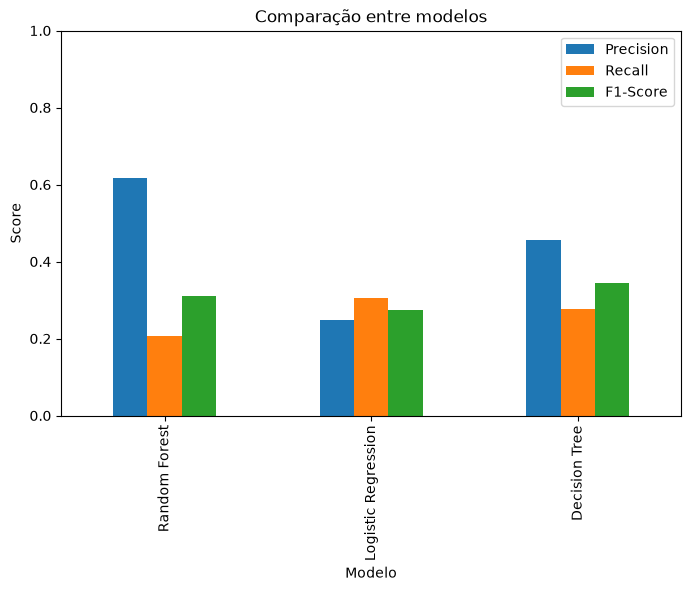

In [105]:
# Gráfico de comparação das métricas
resultados.set_index("Modelo")[["Precision", "Recall", "F1-Score"]].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Comparação entre modelos")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.show()

### Comparação das curvas ROC

A curva ROC é uma métrica importante no modelo de classificação. O gráfico mostra o desempenho do modelo em diferentes lineares de decisão.

- false positive rate, representa a taxa de falsos positivos, ou seja, quantos acidentes **não grave** foram classificadas como **grave**.
- true positive rate, representa o mesmo que o recall, ou seja, quantos **acidentes grave** o modelo conseguiu identificar.

Cada ponto da curva representa um limite na decisão do modelo, quanto mais a curva se aproxima do canto esquerdo melhor é o modelo (alto recall e baixo erro).

In [109]:
# calcular as taxas usando as probabilidades do pipeline
# O [:, 1] pega apenas a probabilidade da classe positiva (1)

y_prob_lr = pipeline_lr.predict_proba(X_test)[:, 1]
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_lr)
auc_log = auc(fpr_log, tpr_log)

y_prob_rf = pipeline_rf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = auc(fpr_rf, tpr_rf)

y_prob_dt = pipeline_dt.predict_proba(X_test)[:, 1]
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
auc_dt = auc(fpr_dt, tpr_dt)

print("Os calculos foram realizados com sucesso!")

Os calculos foram realizados com sucesso!


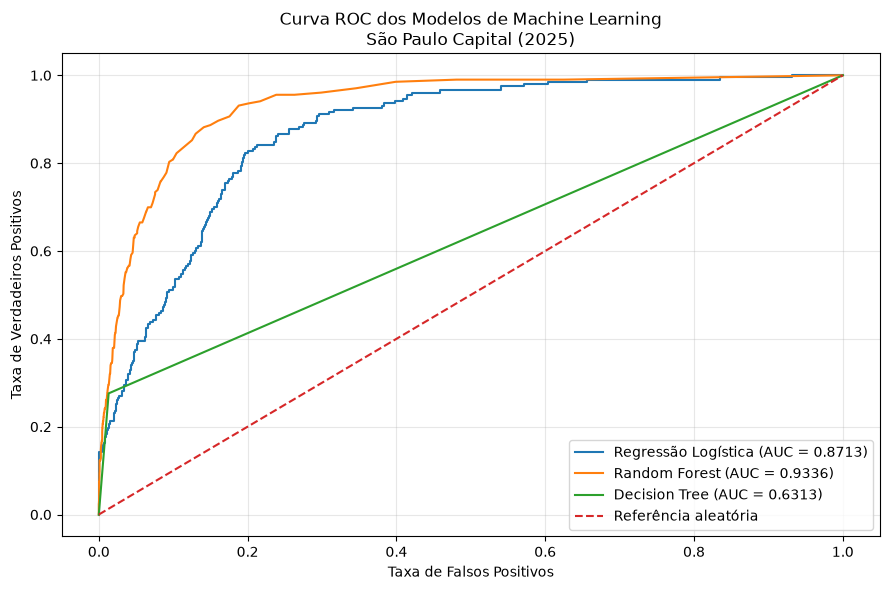

In [110]:
# Criar gráfico da curva ROC
plt.figure(figsize=(9, 6))

plt.plot(
    fpr_log,
    tpr_log,
    label=f"Regressão Logística (AUC = {auc_log:.4f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.4f})"
)

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {auc_dt:.4f})"
)

# Linha de referência
plt.plot([0, 1], [0, 1], linestyle="--", label="Referência aleatória")

plt.title(
    "Curva ROC dos Modelos de Machine Learning\n"
    "São Paulo Capital (2025)"
)

plt.xlabel("Taxa de Falsos Positivos")
plt.ylabel("Taxa de Verdadeiros Positivos")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Salvando a imagem com alta qualidade
plt.savefig(
    "23_curva_roc_modelos_machine_learning_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Comparação das curvas Precision-Recall

A curva precision-recall é outra métrica importante, principalmente em classes desbalanceadas como é o caso. O gráfico mostra o trade-off entre essas duas métricas, ou seja, o equilíbrio entre elas: à medida que uma aumenta, a outra diminui.

- Recall, representa quantos **acidentes graves** o modelo consegue identificar.
- Precision, representa a precisão de quantos **acidentes graves** identificados são realmente **grave**.

In [119]:
# Usamos as mesmas probabilidades calculadas na etapa anterior (y_prob_...)
# Regressão Logística
precision_log, recall_log, _ = precision_recall_curve(
    y_test, y_prob_lr, pos_label=1
)
ap_log = average_precision_score(y_test, y_prob_lr)

# Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(
    y_test, y_prob_rf, pos_label=1
)
ap_rf = average_precision_score(y_test, y_prob_rf)

# Decision Tree
precision_dt, recall_dt, _ = precision_recall_curve(
    y_test, y_prob_dt, pos_label=1
)
ap_dt = average_precision_score(y_test, y_prob_dt)

print("Cálculos realizados com sucesso!")

Cálculos realizados com sucesso!


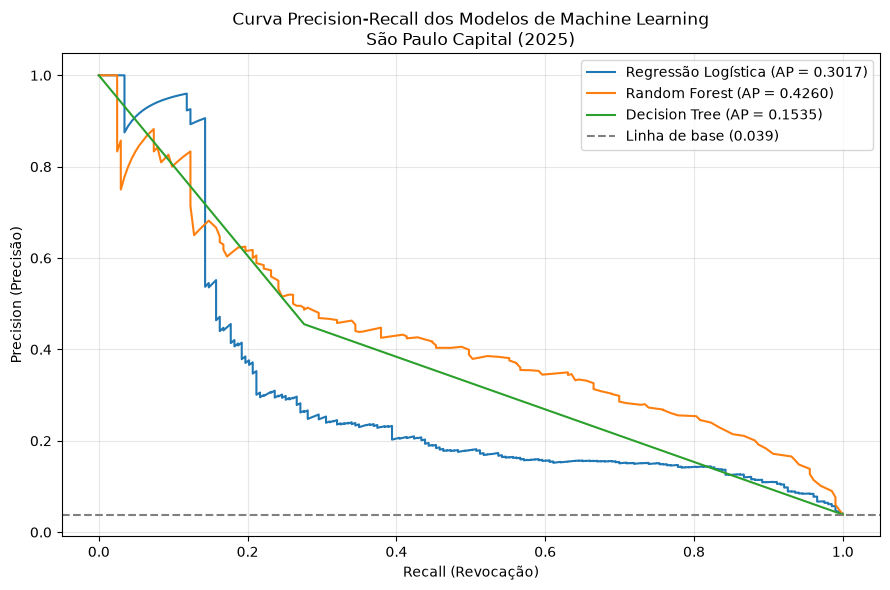

In [120]:
# Gráfico
plt.figure(figsize=(9, 6))

plt.plot(
    recall_log, precision_log,
    label=f"Regressão Logística (AP = {ap_log:.4f})"
)

plt.plot(
    recall_rf, precision_rf,
    label=f"Random Forest (AP = {ap_rf:.4f})"
)

plt.plot(
    recall_dt, precision_dt,
    label=f"Decision Tree (AP = {ap_dt:.4f})"
)

# Proporção de acidentes fatais
proporcao_positivos = (y_test == 1).mean()

plt.axhline(
    y=proporcao_positivos,
    linestyle="--",
    color="gray",
    label=f"Linha de base ({proporcao_positivos:.3f})"
)

plt.title(
    "Curva Precision-Recall dos Modelos de Machine Learning\n"
    "São Paulo Capital (2025)"
)
plt.xlabel("Recall (Revocação)")
plt.ylabel("Precision (Precisão)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "24_curva_precision_recall_modelos_machine_learning_2025.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Matrizes de confusão dos modelos

A matriz de confusão será utilizada para avaliar o desempenho dos modelos de classificação, comparando as classes reais com as previstas. Essa análise permitirá identificar quantos sinistros fatais e não fatais foram classificados corretamente ou incorretamente, destacando possíveis dificuldades na identificação de acidentes fatais.

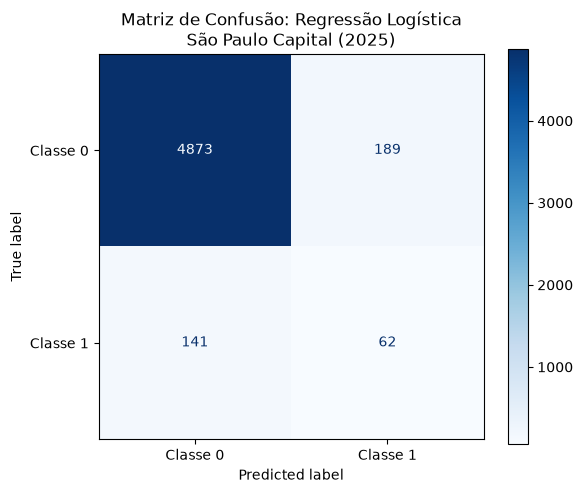

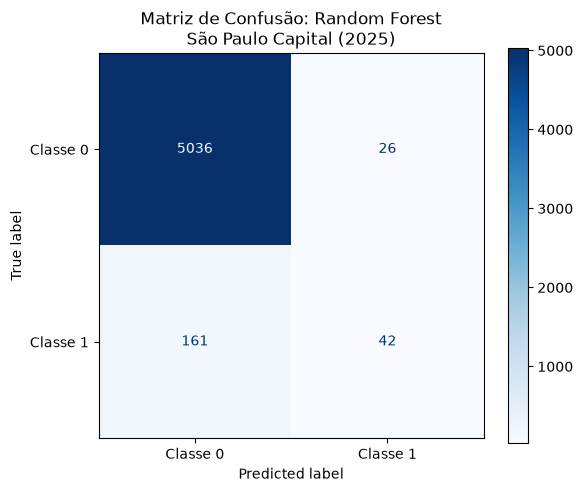

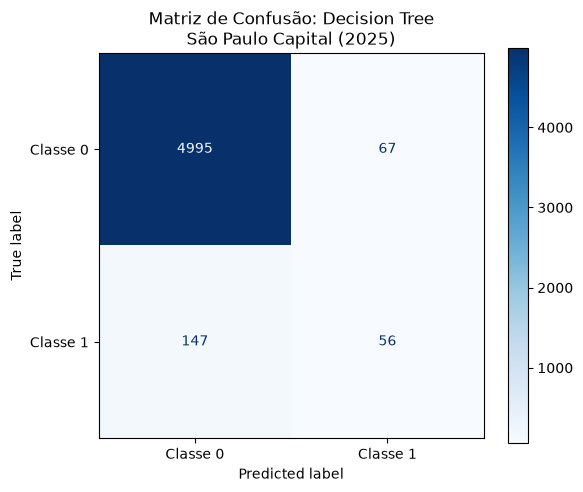

In [121]:
# Matriz de Confusão: Regressão Logística
cm_log = confusion_matrix(y_test, y_pred_lr)
disp_log = ConfusionMatrixDisplay(
    confusion_matrix=cm_log, display_labels=["Classe 0", "Classe 1"]
)

# Renderiza o gráfico do seu jeito
fig, ax = plt.subplots(figsize=(6, 5))
disp_log.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Matriz de Confusão: Regressão Logística\nSão Paulo Capital (2025)")
plt.tight_layout()
plt.savefig(
    "25_matriz_confusao_logistica_2025.png", dpi=300, bbox_inches="tight"
)
plt.show()


# Matriz de Confusão: Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf, display_labels=["Classe 0", "Classe 1"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp_rf.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Matriz de Confusão: Random Forest\nSão Paulo Capital (2025)")
plt.tight_layout()
plt.savefig(
    "26_matriz_confusao_random_forest_2025.png", dpi=300, bbox_inches="tight"
)
plt.show()


# Matriz de Confusão: Decision Tree
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt, display_labels=["Classe 0", "Classe 1"]
)

fig, ax = plt.subplots(figsize=(6, 5))
disp_dt.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Matriz de Confusão: Decision Tree\nSão Paulo Capital (2025)")
plt.tight_layout()
plt.savefig(
    "27_matriz_confusao_decision_tree_2025.png", dpi=300, bbox_inches="tight"
)
plt.show()

## análise de erros (opcional)

Nesta etapa, serão investigadas as previsões incorretas dos modelos para identificar padrões e possíveis limitações na classificação dos sinistros. O objetivo será compreender em quais situações o modelo apresenta maior dificuldade, especialmente na identificação de acidentes fatais, contribuindo para interpretar os resultados e identificar oportunidades de melhoria.

## Conclusão